[ok] saved k_sensitivity.pdf / k_sensitivity.png

=== K-robustness (over the [2,2000] grid) ===
      mapper dataset        score  Kstar  d_at_Kstar  d_mean  d_std  d_min  d_max  frac_p_lt_05
  Supervised    QNLI     Spearman    200       0.333   0.269  0.079  0.052  0.369          0.92
  Supervised    QNLI      Density      3       0.413   0.272  0.118  0.065  0.420          0.81
  Supervised    QNLI          LID     40       0.438   0.348  0.109  0.024  0.454          0.94
  Supervised    QNLI HybridTriple     20       0.515   0.438  0.080  0.280  0.573          1.00
  Supervised   SST-2     Spearman   1800       0.389   0.185  0.149 -0.079  0.393          0.69
  Supervised   SST-2      Density      2       0.176   0.007  0.112 -0.208  0.176          0.19
  Supervised   SST-2          LID    250       0.280   0.233  0.064  0.086  0.349          0.97
  Supervised   SST-2 HybridTriple    500       0.266   0.182  0.045  0.096  0.268          0.81
  Supervised    MNLI     Spearman     40

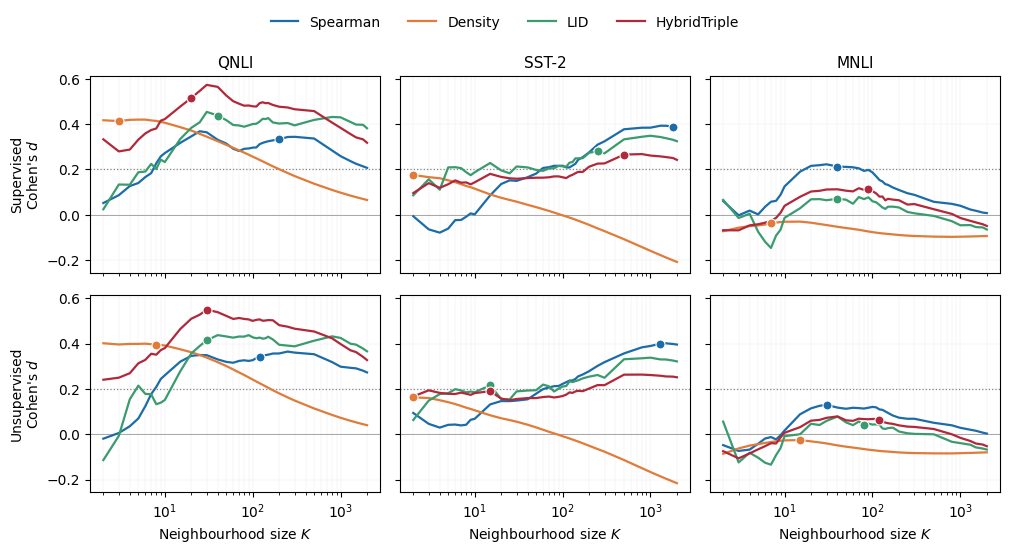

In [1]:
#!/usr/bin/env python3
"""
K-sensitivity analysis for the cross-encoder adversarial-detection protocol.

Rebuts the reviewer concern that selecting K* on the same data used to report
the metric is test-set overfitting. We plot the detection effect size
(Cohen's d) as a function of the neighbourhood size K (log axis) for every
dataset, agreement score, and mapper (supervised / unsupervised). Each curve's
selected K* (argmax of paired direction accuracy) is marked with a dot: a broad
plateau rather than a sharp peak shows the reported numbers are not an artefact
of K selection. The script also prints mean-over-K robustness statistics for
the paper text.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- inputs
FILES = {
    "Supervised":   "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/adv_detection_results_EXTENDED/full_results.csv",
    "Unsupervised": "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/adv_detection_results_EXTENDED_unsupervised/full_results.csv",
}

K_MIN, K_MAX = 2, 2000          # match the K grid stated in the paper
Y   = "cohens_d"                # reported effect size (scale-free)
SEL = "direction_acc"           # the quantity K* maximises

DATASET_ORDER = ["advglue_qnli", "advglue_sst2", "advglue_mnli"]
DATASET_LABEL = {"advglue_qnli": "QNLI", "advglue_sst2": "SST-2", "advglue_mnli": "MNLI"}
METRIC_ORDER  = ["spearman_pw_mean", "density_topk_mean", "lid_mean", "hybrid_triple"]
METRIC_LABEL  = {"spearman_pw_mean": "Spearman", "density_topk_mean": "Density",
                 "lid_mean": "LID", "hybrid_triple": "HybridTriple"}
METRIC_COLOR  = {"spearman_pw_mean": "#1b6ca8", "density_topk_mean": "#e07b39",
                 "lid_mean": "#3a9b6e", "hybrid_triple": "#b1283a"}


def load(path):
    df = pd.read_csv(path)
    return df[(df.K >= K_MIN) & (df.K <= K_MAX)].copy()


# ---------------------------------------------------------------- figure
def make_figure(data, out="k_sensitivity"):
    mappers = list(data.keys())
    nrow, ncol = len(mappers), len(DATASET_ORDER)
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.7 * nrow),
                             sharex=True, sharey=True, squeeze=False)
    for r, mapper in enumerate(mappers):
        df = data[mapper]
        for c, ds in enumerate(DATASET_ORDER):
            ax = axes[r][c]
            sub = df[df.dataset == ds]
            for m in METRIC_ORDER:
                s = sub[sub.metric == m].sort_values("K")
                if s.empty:
                    continue
                ax.plot(s.K, s[Y], color=METRIC_COLOR[m], lw=1.6,
                        label=METRIC_LABEL[m], zorder=2)
                kstar = s.loc[s[SEL].idxmax()]          # this score's own K*
                ax.scatter([kstar.K], [kstar[Y]], color=METRIC_COLOR[m],
                           s=42, edgecolor="white", linewidth=0.8, zorder=3)
            ax.set_xscale("log")
            ax.axhline(0.2, ls=":", color="grey", lw=0.9, zorder=1)   # small effect
            ax.axhline(0.0, ls="-", color="black", lw=0.6, alpha=0.4, zorder=1)
            if r == 0:
                ax.set_title(DATASET_LABEL[ds], fontsize=11)
            if c == 0:
                ax.set_ylabel(f"{mapper}\nCohen's $d$", fontsize=10)
            if r == nrow - 1:
                ax.set_xlabel(r"Neighbourhood size $K$", fontsize=10)
            ax.grid(True, which="both", ls="-", lw=0.3, alpha=0.25)
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 1.03), fontsize=10)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(f"{out}.pdf", bbox_inches="tight")
    fig.savefig(f"{out}.png", dpi=200, bbox_inches="tight")
    print(f"[ok] saved {out}.pdf / {out}.png")


# ----------------------------------------------------------- robustness
def robustness(data):
    rows = []
    for mapper, df in data.items():
        for ds in DATASET_ORDER:
            for m in METRIC_ORDER:
                s = df[(df.dataset == ds) & (df.metric == m)]
                if s.empty:
                    continue
                kstar = s.loc[s[SEL].idxmax()]
                d = s[Y]
                rows.append(dict(
                    mapper=mapper, dataset=DATASET_LABEL[ds], score=METRIC_LABEL[m],
                    Kstar=int(kstar.K), d_at_Kstar=round(float(kstar[Y]), 3),
                    d_mean=round(float(d.mean()), 3), d_std=round(float(d.std()), 3),
                    d_min=round(float(d.min()), 3), d_max=round(float(d.max()), 3),
                    frac_p_lt_05=round(float((s.wilcoxon_p < 0.05).mean()), 2)))
    summary = pd.DataFrame(rows)
    pd.set_option("display.width", 200)
    print("\n=== K-robustness (over the [2,2000] grid) ===")
    print(summary.to_string(index=False))
    summary.to_csv("k_sensitivity_summary.csv", index=False)
    return summary


def main():
    data = {}
    for label, path in FILES.items():
        if os.path.exists(path):
            data[label] = load(path)
        else:
            print(f"[!] missing (skipped): {path}")
    if not data:
        print("No input files found — check the paths in FILES.")
        return
    make_figure(data)
    robustness(data)


if __name__ == "__main__":
    main()